# AI-Assisted Physics Simulation — Topic 8: Pauli Principle and the Periodic Table

**Group members:**

- Manal Almalawi
- Nayla Almuraee
- Asayel Alghamdi
- Joud Alzahrani
- Yara Alamri
- Albatool Alattas
- Shaden Alharthi

**Objectives:**

1. To understand the Pauli Principle and its role in electron configurations.
2. To study how electrons fill atomic subshells according to the Aufbau Principle and the Madelung Rule.
3. To develop a Python simulation that generates electron configurations for elements from Z = 1 to Z = 36.
4. To identify the exceptional electron configurations of Chromium (Cr) and Copper (Cu).
5. To understand the relationship between electron configurations and the periodic table.
6. To validate the simulation by comparing its results with NIST reference data.
7. To study how changing the filling rule (n + αl) affects the accuracy of the results.
8. To compare how fermions and bosons fill the same energy levels.

## Section 0 — Setup and plotting style

**Physics background:** The Pauli exclusion principle says that no two electrons in an atom can have the same four quantum numbers. So each orbital holds at most two electrons (spin up and spin down), and a subshell holds at most 2(2l + 1) electrons: 2 for s, 6 for p, 10 for d and 14 for f. This forces electrons to fill higher subshells, which creates the repeating pattern of the periodic table.

In [1]:
# Cell 2 — Imports and plotting style
# We only use NumPy (numbers/arrays), pandas (tables) and Matplotlib (plots).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# One colour palette used by every figure, so all plots look consistent.
COLORS = {
    "background": "#FAFAF7",   # off-white page colour
    "text":       "#333333",   # dark grey for text and axes
    "blue":       "#4C72B0",
    "teal":       "#44AA99",
    "orange":     "#DD8452",
    "purple":     "#8172B3",
    "grid":       "#BBBBBB",   # light grey for gridlines
}

# Font sizes (in points) for the different parts of a figure.
FONT = {"title": 15, "label": 12, "tick": 11, "legend": 11}

# Colours used when styling the pandas table in Section 4.
TABLE_HEADER_COLOR = "#E8EEF4"     # light blue-grey header
TABLE_EXCEPTION_COLOR = "#FCEBD9"  # soft orange for exception rows

# Apply all settings once; every later figure inherits them automatically.
plt.rcParams.update({
    "figure.facecolor": COLORS["background"],
    "axes.facecolor":   COLORS["background"],
    "savefig.facecolor": COLORS["background"],
    "text.color":       COLORS["text"],
    "axes.labelcolor":  COLORS["text"],
    "axes.edgecolor":   COLORS["text"],
    "xtick.color":      COLORS["text"],
    "ytick.color":      COLORS["text"],
    "axes.titlesize":   FONT["title"],
    "axes.labelsize":   FONT["label"],
    "xtick.labelsize":  FONT["tick"],
    "ytick.labelsize":  FONT["tick"],
    "legend.fontsize":  FONT["legend"],
    "axes.grid":        True,          # show gridlines
    "grid.color":       COLORS["grid"],
    "grid.linewidth":   0.6,           # thin lines
    "grid.alpha":       0.3,           # very light
    "axes.spines.top":   False,        # remove the top border
    "axes.spines.right": False,        # remove the right border
    "figure.figsize":   (9, 4.5),      # default figure size in inches
    "figure.dpi":       110,           # resolution on screen
})

print("Style loaded.")

Style loaded.


## Section 1 — Physical parameters

**Physics background:** This section explains the basic things we use to study atoms and their electrons. We looked at 36 elements, from hydrogen (H) to krypton (Kr). Electrons are arranged in four types of subshells, and each type has a limit on how many electrons it can hold:

- s: 2 electrons
- p: 6 electrons
- d: 10 electrons
- f: 14 electrons

We also learned the symbols of the elements, found the noble gases, and noticed two elements that don't follow the normal pattern: chromium (Cr) and copper (Cu).

In [2]:
# Cell 4 — Parameters of the model
Z_MAX = 36   # we study the neutral atoms Z = 1 ... 36 (H to Kr)
N_MAX = 7    # largest principal quantum number n we allow
L_MAX = 3    # largest orbital quantum number l we allow (l = 3 is "f")

# Spectroscopic letter for each value of l.
SUBSHELL_LETTERS = {0: "s", 1: "p", 2: "d", 3: "f"}


def subshell_capacity(l):
    """Maximum number of electrons in a subshell with orbital number l.

    There are (2l + 1) values of m_l, and the Pauli principle allows two
    electrons (spin up and spin down) in each, so the capacity is 2(2l + 1).
    """
    return 2 * (2 * l + 1)


# Capacity for every l we use: {0: 2, 1: 6, 2: 10, 3: 14}
CAPACITY = {l: subshell_capacity(l) for l in SUBSHELL_LETTERS}

# Chemical symbols; SYMBOLS[Z - 1] is the element with atomic number Z.
SYMBOLS = ["H", "He", "Li", "Be", "B", "C", "N", "O", "F", "Ne",
           "Na", "Mg", "Al", "Si", "P", "S", "Cl", "Ar",
           "K", "Ca", "Sc", "Ti", "V", "Cr", "Mn", "Fe", "Co", "Ni",
           "Cu", "Zn", "Ga", "Ge", "As", "Se", "Br", "Kr"]

# Z_MAX can be anything from 1 up to the number of symbols we have (36).
assert 1 <= Z_MAX <= len(SYMBOLS), f"Z_MAX must be between 1 and {len(SYMBOLS)}"

# Noble gases up to Kr, used for the shorthand notation "[Ar] ...".
NOBLE_GASES = {2: "He", 10: "Ne", 18: "Ar", 36: "Kr"}

# Known exceptions for Z <= 36. Each entry OVERWRITES the Aufbau result
# for the listed (n, l) subshells.  (3, 2) = 3d and (4, 0) = 4s.
EXCEPTIONS = {
    24: {(3, 2): 5,  (4, 0): 1},   # Cr: [Ar] 3d5 4s1
    29: {(3, 2): 10, (4, 0): 1},   # Cu: [Ar] 3d10 4s1
}

In [3]:
# Cell 5 — Test: capacities and symbols
for l, letter in SUBSHELL_LETTERS.items():
    print(f"l = {l} ({letter}): capacity = {CAPACITY[l]}")

print()
print("Symbols available:", len(SYMBOLS), f"({SYMBOLS[0]} to {SYMBOLS[-1]})")
print("Elements studied :", Z_MAX, f"({SYMBOLS[0]} to {SYMBOLS[Z_MAX - 1]})")
assert len(SYMBOLS) >= Z_MAX   # there must be a symbol for every Z we study
assert CAPACITY == {0: 2, 1: 6, 2: 10, 3: 14}

l = 0 (s): capacity = 2
l = 1 (p): capacity = 6
l = 2 (d): capacity = 10
l = 3 (f): capacity = 14

Symbols available: 36 (H to Kr)
Elements studied : 36 (H to Kr)


## Section 2 — The Madelung (n + l) filling order

**Physics background:** The Madelung rule shows the order in which electrons fill subshells using (n + l). The subshell with the lower (n + l) value fills first. If two subshells have the same value, the one with the lower n fills first. This rule helps us predict electron configurations.

In [4]:
# Cell 7 — Madelung order
def subshell_label(n, l):
    """Return the usual name of a subshell, e.g. (3, 2) -> "3d"."""
    return f"{n}{SUBSHELL_LETTERS[l]}"


def madelung_key(subshell):
    """Sorting key for the Madelung rule.

    Python sorts tuples element by element: first by n + l,
    and if two subshells have the same n + l, by n (lower n first).
    """
    n, l = subshell
    return (n + l, n)


def madelung_order(n_max, l_max):
    """List of all allowed (n, l) pairs, sorted by the Madelung rule."""
    subshells = []
    for n in range(1, n_max + 1):
        # l can only go from 0 to n - 1 (and we stop at l_max).
        for l in range(0, min(n - 1, l_max) + 1):
            subshells.append((n, l))
    return sorted(subshells, key=madelung_key)


# Computed once and reused everywhere below.
MADELUNG_ORDER = madelung_order(N_MAX, L_MAX)

In [5]:
# Cell 8 — Test: print the order and a small table of n, l, n + l
first_12 = [subshell_label(n, l) for (n, l) in MADELUNG_ORDER[:12]]
print(" ".join(first_12))
assert " ".join(first_12) == "1s 2s 2p 3s 3p 4s 3d 4p 5s 4d 5p 6s"

order_table = pd.DataFrame({
    "Subshell": [subshell_label(n, l) for (n, l) in MADELUNG_ORDER],
    "n":        [n for (n, l) in MADELUNG_ORDER],
    "l":        [l for (n, l) in MADELUNG_ORDER],
    "n + l":    [n + l for (n, l) in MADELUNG_ORDER],
})
print()
print(order_table.to_string(index=False))

1s 2s 2p 3s 3p 4s 3d 4p 5s 4d 5p 6s

Subshell  n  l  n + l
      1s  1  0      1
      2s  2  0      2
      2p  2  1      3
      3s  3  0      3
      3p  3  1      4
      4s  4  0      4
      3d  3  2      5
      4p  4  1      5
      5s  5  0      5
      4d  4  2      6
      5p  5  1      6
      6s  6  0      6
      4f  4  3      7
      5d  5  2      7
      6p  6  1      7
      7s  7  0      7
      5f  5  3      8
      6d  6  2      8
      7p  7  1      8
      6f  6  3      9
      7d  7  2      9
      7f  7  3     10


## Section 3 — Filling the subshells (Aufbau)

**Physics background:** In this part we studied how electrons are distributed in the subshells according to the Aufbau principle. Electrons fill the lower energy levels first and each subshell has a specific number of electrons. We also noticed some exceptions such as chromium and copper, because their electrons rearrange to reach a more stable state.

In [6]:
# Cell 10 — Filling functions
def fill_aufbau(Z, order=MADELUNG_ORDER):
    """Put Z electrons into the subshells in the given order.

    Each subshell takes as many electrons as it can (its capacity),
    until no electrons are left.  Returns {(n, l): electrons}.
    """
    config = {}
    remaining = Z                                  # electrons still to place
    for (n, l) in order:
        if remaining == 0:
            break                                  # all electrons placed
        electrons = min(remaining, CAPACITY[l])    # fill as much as allowed
        config[(n, l)] = electrons
        remaining -= electrons
    return config


def electron_configuration(Z, order=MADELUNG_ORDER, apply_exceptions=True):
    """Ground-state configuration of the neutral atom Z.

    Returns the pair (configuration, is_exception), where is_exception
    is True when an entry of EXCEPTIONS was applied.
    """
    config = fill_aufbau(Z, order)
    is_exception = False
    if apply_exceptions and Z in EXCEPTIONS:
        config.update(EXCEPTIONS[Z])               # overwrite those subshells
        is_exception = True
    # Remove any subshell that ended up empty (0 electrons).
    config = {sub: e for sub, e in config.items() if e > 0}
    return config, is_exception

In [7]:
# Cell 11 — Test: a few elements
for Z in [11, 24, 26, 29, 36]:          # Na, Cr, Fe, Cu, Kr
    config, is_exc = electron_configuration(Z)
    print(f"{SYMBOLS[Z - 1]:>2} (Z = {Z}): {config}   exception = {is_exc}")

print()
config_cr_pure, _ = electron_configuration(24, apply_exceptions=False)
print("Cr with pure Aufbau:", config_cr_pure)

Na (Z = 11): {(1, 0): 2, (2, 0): 2, (2, 1): 6, (3, 0): 1}   exception = False
Cr (Z = 24): {(1, 0): 2, (2, 0): 2, (2, 1): 6, (3, 0): 2, (3, 1): 6, (4, 0): 1, (3, 2): 5}   exception = True
Fe (Z = 26): {(1, 0): 2, (2, 0): 2, (2, 1): 6, (3, 0): 2, (3, 1): 6, (4, 0): 2, (3, 2): 6}   exception = False
Cu (Z = 29): {(1, 0): 2, (2, 0): 2, (2, 1): 6, (3, 0): 2, (3, 1): 6, (4, 0): 1, (3, 2): 10}   exception = True
Kr (Z = 36): {(1, 0): 2, (2, 0): 2, (2, 1): 6, (3, 0): 2, (3, 1): 6, (4, 0): 2, (3, 2): 10, (4, 1): 6}   exception = False

Cr with pure Aufbau: {(1, 0): 2, (2, 0): 2, (2, 1): 6, (3, 0): 2, (3, 1): 6, (4, 0): 2, (3, 2): 4}


## Section 4 — Writing the configurations and the summary table

### 4.1 Text formatting

**Physics background:** In this part, the code shows electron configurations from hydrogen (Z = 1) to krypton (Z = 36). We used two ways, the full way and the short way using noble gases, to show the outer electrons clearly.

In [8]:
# Cell 13 — Formatting functions
def format_full(config, sort_by_n=True):
    """Turn {(n, l): electrons} into text like "1s2 2s2 2p6".

    sort_by_n=True writes the subshells sorted by n, then l (usual notation);
    sort_by_n=False keeps the order in which they were filled.
    """
    subshells = sorted(config) if sort_by_n else list(config)
    parts = [f"{subshell_label(n, l)}{config[(n, l)]}" for (n, l) in subshells]
    return " ".join(parts)


def noble_gas_core(Z):
    """Atomic number of the largest noble gas with Z_core < Z (0 if none)."""
    core = 0
    for Z_gas in NOBLE_GASES:
        if Z_gas < Z:
            core = Z_gas
    return core


def format_shorthand(Z, apply_exceptions=True, sort_by_n=True):
    """Configuration in noble-gas shorthand, e.g. "[Ar] 3d5 4s1"."""
    config, _ = electron_configuration(Z, apply_exceptions=apply_exceptions)
    Z_core = noble_gas_core(Z)
    if Z_core == 0:                       # H and He have no noble-gas core
        return format_full(config, sort_by_n)

    core_config, _ = electron_configuration(Z_core)
    # Keep only the electrons that are NOT part of the core.
    outer = {}
    for sub, e in config.items():
        extra = e - core_config.get(sub, 0)
        if extra > 0:
            outer[sub] = extra
    return f"[{NOBLE_GASES[Z_core]}] " + format_full(outer, sort_by_n)

In [9]:
# Cell 14 — Test: full and shorthand notation
for Z in [11, 24, 26, 29, 36]:          # Na, Cr, Fe, Cu, Kr
    config, _ = electron_configuration(Z)
    print(f"{SYMBOLS[Z - 1]:>2}: {format_full(config):<40} {format_shorthand(Z)}")

Na: 1s2 2s2 2p6 3s1                          [Ne] 3s1
Cr: 1s2 2s2 2p6 3s2 3p6 3d5 4s1              [Ar] 3d5 4s1
Fe: 1s2 2s2 2p6 3s2 3p6 3d6 4s2              [Ar] 3d6 4s2
Cu: 1s2 2s2 2p6 3s2 3p6 3d10 4s1             [Ar] 3d10 4s1
Kr: 1s2 2s2 2p6 3s2 3p6 3d10 4s2 4p6         [Ar] 3d10 4s2 4p6


### 4.2 Configuration table for Z = 1 to 36

**Physics background:** In this part, we put the results in a table and used orange for the elements that break the Aufbau rule. The result shows 34 elements follow the rule and only two elements break it, chromium (Cr) and copper (Cu). This happens because atoms are more stable when the 3d shell is half full or completely full.

In [10]:
# Cell 16 — Build and style the configuration table
rows = []
for Z in range(1, Z_MAX + 1):
    config, is_exc = electron_configuration(Z)
    rows.append({
        "Z": Z,
        "Element": SYMBOLS[Z - 1],
        "Full configuration": format_full(config),
        "Shorthand": format_shorthand(Z),
        "Exception": "YES" if is_exc else "",
        # Only filled for the exceptions: what the plain rule would predict.
        "Pure Aufbau would give": format_shorthand(Z, apply_exceptions=False) if is_exc else "",
    })
config_table = pd.DataFrame(rows)


def highlight_exceptions(row):
    """Soft-orange, bold style for exception rows; no style otherwise."""
    if row["Exception"] == "YES":
        style = f"background-color: {TABLE_EXCEPTION_COLOR}; font-weight: bold"
    else:
        style = ""
    return [style] * len(row)


styled_table = (
    config_table.style
    .apply(highlight_exceptions, axis=1)              # colour row by row
    .set_table_styles([{"selector": "th",              # header cells
                        "props": [("background-color", TABLE_HEADER_COLOR),
                                  ("color", COLORS["text"])]}])
    .hide(axis="index")                                # Z column is enough
)

In [11]:
# Cell 17 — Test: size of the table, the exception rows, then the full table
print("Table shape:", config_table.shape, "(rows, columns)")
print()
print(config_table[config_table["Exception"] == "YES"].to_string(index=False))
styled_table   # the last line of a cell is displayed by Jupyter

Table shape: (36, 6) (rows, columns)

 Z Element           Full configuration     Shorthand Exception Pure Aufbau would give
24      Cr  1s2 2s2 2p6 3s2 3p6 3d5 4s1  [Ar] 3d5 4s1       YES           [Ar] 3d4 4s2
29      Cu 1s2 2s2 2p6 3s2 3p6 3d10 4s1 [Ar] 3d10 4s1       YES           [Ar] 3d9 4s2


Z,Element,Full configuration,Shorthand,Exception,Pure Aufbau would give
1,H,1s1,1s1,,
2,He,1s2,1s2,,
3,Li,1s2 2s1,[He] 2s1,,
4,Be,1s2 2s2,[He] 2s2,,
5,B,1s2 2s2 2p1,[He] 2s2 2p1,,
6,C,1s2 2s2 2p2,[He] 2s2 2p2,,
7,N,1s2 2s2 2p3,[He] 2s2 2p3,,
8,O,1s2 2s2 2p4,[He] 2s2 2p4,,
9,F,1s2 2s2 2p5,[He] 2s2 2p5,,
10,Ne,1s2 2s2 2p6,[He] 2s2 2p6,,


## Section 5 — Validation against NIST SRD 111

**Physics background:** In this part, we check the accuracy of the electron configuration model by comparing the results to NIST data for 36 elements. The Madelung rule alone gave 34 correct answers out of 36, an accuracy of 94.4%. The two incorrect elements were chromium (Cr) and copper (Cu). After adding these two elements as exceptions, all 36 results became correct (100%). The 100% is reached only because Cr and Cu were added by hand; the rule alone gives 34/36.

The reference data below are in NIST notation: an exponent of 1 is not written (e.g. `4s` means `4s1`).

In [12]:
# Cell 19 — Reference data (NIST SRD 111, ground-state configurations)
# Source: NIST Standard Reference Database 111,
# "Ground Levels and Ionization Energies for the Neutral Atoms".
NIST_SRD111 = {
    1: "1s",                2: "1s2",
    3: "[He] 2s",           4: "[He] 2s2",
    5: "[He] 2s2 2p",       6: "[He] 2s2 2p2",
    7: "[He] 2s2 2p3",      8: "[He] 2s2 2p4",
    9: "[He] 2s2 2p5",     10: "[He] 2s2 2p6",
    11: "[Ne] 3s",         12: "[Ne] 3s2",
    13: "[Ne] 3s2 3p",     14: "[Ne] 3s2 3p2",
    15: "[Ne] 3s2 3p3",    16: "[Ne] 3s2 3p4",
    17: "[Ne] 3s2 3p5",    18: "[Ne] 3s2 3p6",
    19: "[Ar] 4s",         20: "[Ar] 4s2",
    21: "[Ar] 3d 4s2",     22: "[Ar] 3d2 4s2",
    23: "[Ar] 3d3 4s2",    24: "[Ar] 3d5 4s",
    25: "[Ar] 3d5 4s2",    26: "[Ar] 3d6 4s2",
    27: "[Ar] 3d7 4s2",    28: "[Ar] 3d8 4s2",
    29: "[Ar] 3d10 4s",    30: "[Ar] 3d10 4s2",
    31: "[Ar] 3d10 4s2 4p",  32: "[Ar] 3d10 4s2 4p2",
    33: "[Ar] 3d10 4s2 4p3", 34: "[Ar] 3d10 4s2 4p4",
    35: "[Ar] 3d10 4s2 4p5", 36: "[Ar] 3d10 4s2 4p6",
}

# Change to "YES" only after the group has checked every entry against NIST.
REFERENCE_CHECKED_BY_GROUP = "NO"

# Reverse look-ups: letter -> l, and gas symbol -> Z.
LETTER_TO_L = {letter: l for l, letter in SUBSHELL_LETTERS.items()}
GAS_TO_Z = {symbol: Z for Z, symbol in NOBLE_GASES.items()}


def expand_reference(text):
    """Turn NIST text like "[Ar] 3d5 4s" into {(n, l): electrons}."""
    config = {}
    text = text.replace("]", "] ")             # also accept "[Ar]3d5"
    for token in text.split():
        if token.startswith("["):
            # Noble-gas core: replace "[Ar]" by Ar's own reference configuration.
            gas = token.strip("[]")
            config.update(expand_reference(NIST_SRD111[GAS_TO_Z[gas]]))
        else:
            n = int(token[0])                   # e.g. "3d10" -> n = 3
            l = LETTER_TO_L[token[1]]           #             -> l = 2
            exponent = token[2:]                #             -> "10"
            config[(n, l)] = int(exponent) if exponent else 1   # no exponent = 1
    return config


print("Reference checked by group:", REFERENCE_CHECKED_BY_GROUP)
print("Example: expand_reference('[Ar] 3d5 4s') =", expand_reference("[Ar] 3d5 4s"))

Reference checked by group: NO
Example: expand_reference('[Ar] 3d5 4s') = {(1, 0): 2, (2, 0): 2, (2, 1): 6, (3, 0): 2, (3, 1): 6, (3, 2): 5, (4, 0): 1}


In [13]:
# Cell 20 — Compare the model with the reference
def count_matches(order=MADELUNG_ORDER, apply_exceptions=True):
    """Return the list of Z values where the model equals the reference."""
    matches = []
    for Z in range(1, Z_MAX + 1):
        model, _ = electron_configuration(Z, order, apply_exceptions)
        if model == expand_reference(NIST_SRD111[Z]):   # dicts: same keys and values
            matches.append(Z)
    return matches


for label, use_exc in [("Pure Madelung", False), ("Madelung + exceptions", True)]:
    matches = count_matches(apply_exceptions=use_exc)
    wrong = [SYMBOLS[Z - 1] for Z in range(1, Z_MAX + 1) if Z not in matches]
    percent = 100 * len(matches) / Z_MAX
    print(f"{label:<22}: {len(matches)}/{Z_MAX} match ({percent:.1f} %)   wrong: {wrong}")

# Physical consistency checks on the final configurations.
for Z in range(1, Z_MAX + 1):
    config, _ = electron_configuration(Z)
    assert sum(config.values()) == Z, f"Z = {Z}: electron total is not Z"
    for (n, l), e in config.items():
        assert e <= CAPACITY[l], f"Z = {Z}: {subshell_label(n, l)} exceeds its capacity"
print()
print("Check passed: electron total = Z for every element.")
print("Check passed: no subshell exceeds 2(2l + 1).")

Pure Madelung         : 34/36 match (94.4 %)   wrong: ['Cr', 'Cu']
Madelung + exceptions : 36/36 match (100.0 %)   wrong: []

Check passed: electron total = Z for every element.
Check passed: no subshell exceeds 2(2l + 1).


## Section 6 — Parameter study

**Physics background:** Here we looked at how the atomic number (Z) is connected to the number of electrons in the outer shell. The number rises from 1 to 8 across periods 2 and 3, then drops to 1 after each noble gas. In period 4 it stays at 2 from Ca to Zn, because the 3d electrons belong to the inner shell (n = 3). It dips to 1 at Cr and Cu, where one 4s electron moves into 3d. This repeating pattern is what makes the periodic table organized.

### 6.1 Outer-shell electrons

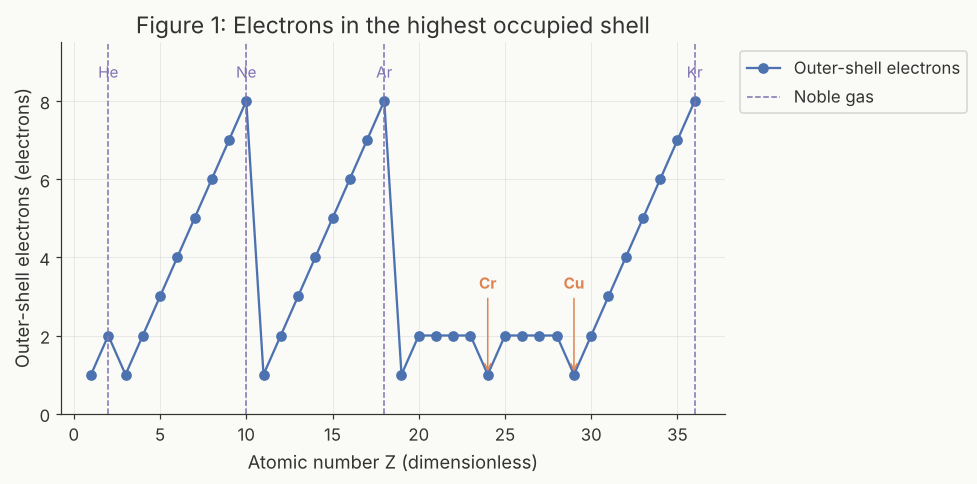

In [14]:
# Cell 22 — Figure 1: outer-shell electrons against Z
def outer_shell_electrons(config):
    """Electrons in the highest occupied shell n."""
    n_highest = max(n for (n, l) in config)
    return sum(e for (n, l), e in config.items() if n == n_highest)


Z_values = np.arange(1, Z_MAX + 1)
outer = np.array([outer_shell_electrons(electron_configuration(Z)[0]) for Z in Z_values])

fig, ax = plt.subplots()
ax.plot(Z_values, outer, marker="o", color=COLORS["blue"], label="Outer-shell electrons")

# Dashed vertical lines at the noble gases.
first_line = True
for Z_gas, gas in NOBLE_GASES.items():
    if Z_gas > Z_MAX:
        continue                          # this gas is outside the studied range
    ax.axvline(Z_gas, linestyle="--", color=COLORS["purple"], linewidth=1,
               label="Noble gas" if first_line else None)   # only one legend entry
    first_line = False
    ax.text(Z_gas, outer.max() + 0.6, gas, ha="center", color=COLORS["purple"])

# Labels on the two exceptions (only if they are inside the studied range).
for Z_exc in EXCEPTIONS:
    if Z_exc > Z_MAX:
        continue
    ax.annotate(SYMBOLS[Z_exc - 1], xy=(Z_exc, outer[Z_exc - 1]),
                xytext=(Z_exc, outer[Z_exc - 1] + 2.2), ha="center",
                color=COLORS["orange"], fontweight="bold",
                arrowprops={"arrowstyle": "->", "color": COLORS["orange"]})

ax.set_xlabel("Atomic number Z (dimensionless)")
ax.set_ylabel("Outer-shell electrons (electrons)")
ax.set_title("Figure 1: Electrons in the highest occupied shell")
ax.set_ylim(0, outer.max() + 1.5)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))   # legend outside, right
fig.tight_layout()
plt.show()

*Figure 1 caption:* The bottom line of the graph shows the atomic number (Z), and the side line shows the number of outer-shell electrons. The purple dashed lines mark the noble gases (He, Ne, Ar and Kr). Cr and Cu are special cases because each one has only one electron in its outer shell.

### 6.2 Changing the ordering rule: n + α·l

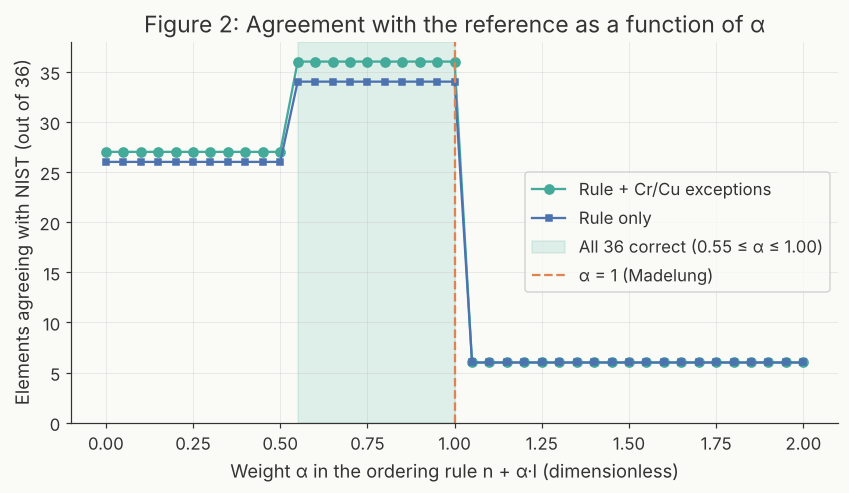

alpha values where all 36 are correct: [0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]


In [15]:
# Cell 25 — Figure 2: sweep the ordering rule n + alpha * l
def general_order(alpha, n_max=N_MAX, l_max=L_MAX):
    """Subshells sorted by (n + alpha*l), ties broken by lower n.

    alpha = 1 gives back the Madelung rule.  round() removes tiny
    floating-point errors so that exact ties are recognised as ties.
    """
    subshells = [(n, l) for n in range(1, n_max + 1)
                 for l in range(0, min(n - 1, l_max) + 1)]
    return sorted(subshells, key=lambda s: (round(s[0] + alpha * s[1], 10), s[0]))


# Sanity check: alpha = 1 must reproduce the Madelung order.
assert general_order(1.0) == MADELUNG_ORDER

alphas = np.round(np.arange(0, 2.0001, 0.05), 2)     # 0.00, 0.05, ..., 2.00
correct_pure = []    # matches using only the ordering rule
correct_exc = []     # matches using the rule + the Cr/Cu exceptions
for alpha in alphas:
    order = general_order(alpha)
    correct_pure.append(len(count_matches(order, apply_exceptions=False)))
    correct_exc.append(len(count_matches(order, apply_exceptions=True)))
correct_pure = np.array(correct_pure)
correct_exc = np.array(correct_exc)

fig, ax = plt.subplots()
ax.plot(alphas, correct_exc, marker="o", color=COLORS["teal"], label="Rule + Cr/Cu exceptions")
ax.plot(alphas, correct_pure, marker="s", markersize=4, color=COLORS["blue"], label="Rule only")

# Shade the alpha range where all Z_MAX elements are correct.
all_ok = alphas[correct_exc == Z_MAX]
if len(all_ok) > 0:
    ax.axvspan(all_ok.min(), all_ok.max(), color=COLORS["teal"], alpha=0.15,
               label=f"All {Z_MAX} correct ({all_ok.min():.2f} ≤ α ≤ {all_ok.max():.2f})")
ax.axvline(1.0, linestyle="--", color=COLORS["orange"], label="α = 1 (Madelung)")

ax.set_xlabel("Weight α in the ordering rule n + α·l (dimensionless)")
ax.set_ylabel(f"Elements agreeing with NIST (out of {Z_MAX})")
ax.set_title("Figure 2: Agreement with the reference as a function of α")
ax.set_ylim(0, Z_MAX + 2)
ax.legend(loc="center right")
plt.show()

print(f"alpha values where all {Z_MAX} are correct:", [float(a) for a in all_ok])

*Figure 2 caption:* This figure shows how changing α affects the number of correct electron configurations out of 36 elements. When α ≤ 0.50, only 26–27 elements are correct, because 3d fills before 4s. When 0.55 ≤ α ≤ 1.00 (shaded area), the rule gives 34/36 correct results, and 36/36 after adding the Cr and Cu exceptions. When α > 1, 3s fills before 2p, so configurations go wrong from boron (Z = 5) onward and only about 6 elements are correct. The dashed line at α = 1 represents the Madelung rule.

### 6.3 Simple n-ordering compared with Madelung

**Physics background:** Since there is only one electron in a hydrogen atom, its energy depends only on n, so we might expect the subshells to fill in the order of n. In atoms with several electrons, the inner electrons shield part of the nucleus's attraction from the outer electrons. An electron in an s subshell can get closer to the nucleus than an electron in a d subshell, so it is less shielded and has lower energy. This is why 4s fills before 3d. The correct order is given by the Madelung rule, where each subshell is labelled by n + l, and the lower value of n + l fills first. Both rules were tested on elements 1–36 and compared with NIST.

Wrong with n-ordering : ['K', 'Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni'] (10 elements)
Wrong with Madelung   : ['Cr', 'Cu'] (2 elements)


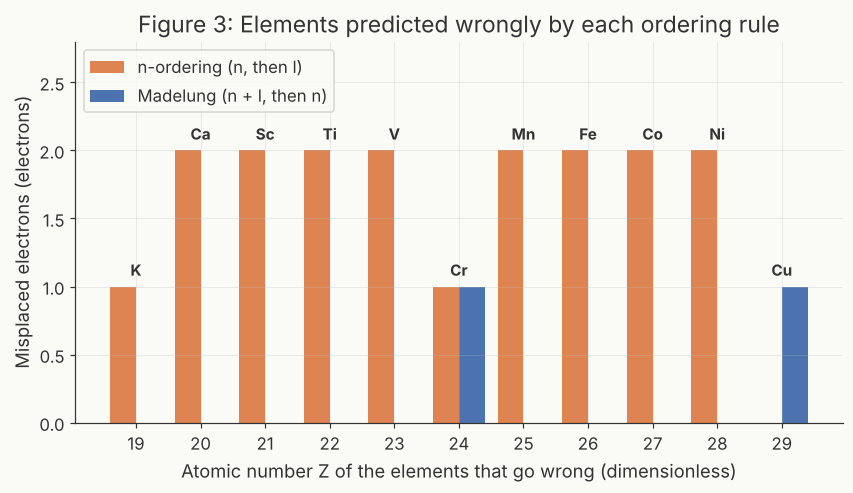

In [16]:
# Cell 28 — Figure 3: n-ordering (n first, then l) versus Madelung
# Sorting the (n, l) tuples directly gives 1s 2s 2p 3s 3p 3d 4s 4p ...
N_ORDER = sorted(MADELUNG_ORDER)


def misplaced_electrons(model, reference):
    """Number of electrons sitting in the wrong subshell.

    Each misplaced electron is counted twice (missing in one subshell,
    extra in another), so we divide the total difference by 2.
    """
    all_subshells = set(model) | set(reference)
    diff = sum(abs(model.get(s, 0) - reference.get(s, 0)) for s in all_subshells)
    return diff // 2


wrong_n = {}         # Z -> misplaced electrons for the n-ordering
wrong_madelung = {}  # Z -> misplaced electrons for pure Madelung
for Z in range(1, Z_MAX + 1):
    ref = expand_reference(NIST_SRD111[Z])
    m_n = misplaced_electrons(electron_configuration(Z, N_ORDER, False)[0], ref)
    m_mad = misplaced_electrons(electron_configuration(Z, MADELUNG_ORDER, False)[0], ref)
    if m_n > 0:
        wrong_n[Z] = m_n
    if m_mad > 0:
        wrong_madelung[Z] = m_mad

print("Wrong with n-ordering :", [SYMBOLS[Z - 1] for Z in wrong_n], f"({len(wrong_n)} elements)")
print("Wrong with Madelung   :", [SYMBOLS[Z - 1] for Z in wrong_madelung], f"({len(wrong_madelung)} elements)")

# Bar chart: two bars per element, side by side.
Z_wrong = sorted(set(wrong_n) | set(wrong_madelung))
x = np.arange(len(Z_wrong))
h_n = np.array([wrong_n.get(Z, 0) for Z in Z_wrong])
h_mad = np.array([wrong_madelung.get(Z, 0) for Z in Z_wrong])
width = 0.4

fig, ax = plt.subplots()
if len(Z_wrong) == 0:
    # For small Z_MAX both rules are correct, so there are no bars to draw.
    ax.text(0.5, 0.5, f"No element is predicted wrongly for Z ≤ {Z_MAX}",
            ha="center", va="center", transform=ax.transAxes)
else:
    ax.bar(x - width / 2, h_n, width, color=COLORS["orange"], label="n-ordering (n, then l)")
    ax.bar(x + width / 2, h_mad, width, color=COLORS["blue"], label="Madelung (n + l, then n)")

    # Element symbol above each pair of bars.
    for xi, Z, top in zip(x, Z_wrong, np.maximum(h_n, h_mad)):
        ax.text(xi, top + 0.08, SYMBOLS[Z - 1], ha="center", fontweight="bold")

    ax.set_xticks(x)
    ax.set_xticklabels([str(Z) for Z in Z_wrong])
    ax.set_ylim(0, max(h_n.max(), h_mad.max()) + 0.8)
    ax.legend(loc="upper left")

ax.set_xlabel("Atomic number Z of the elements that go wrong (dimensionless)")
ax.set_ylabel("Misplaced electrons (electrons)")
ax.set_title("Figure 3: Elements predicted wrongly by each ordering rule")
plt.show()

*Figure 3 caption:* The bars show how many electrons are in the wrong place for each element.

- Orange: filling by n only
- Blue: Madelung rule

Elements not shown in the chart are correct under both rules. Filling by n alone fails for 10 elements (K to Ni), because it puts 3d before 4s. Madelung fails only for Cr and Cu (1 electron each), the known exceptions.

## Section 7 — Extension: fermions versus bosons

Equally spaced levels $E_k = (k + \tfrac{1}{2})\,\hbar\omega$, with $k = 0, 1, 2, \dots$
Spin-½ fermions: at most 2 particles per level. Bosons: no limit.

**Physics background:** Particles fill energy levels starting from the lowest. Due to the Pauli principle, each level can hold at most two fermions while bosons have no limit.

In [17]:
# Cell 31 — Filling equally spaced levels
N_LEVELS = 20   # enough levels for up to 40 fermions


def level_energy(k):
    """Energy of level k in units of hbar*omega: E_k = k + 1/2."""
    return k + 0.5


def fill_levels(N, max_per_level):
    """Put N particles into the lowest levels, at most max_per_level each.

    Returns an array: occupation[k] = number of particles in level k.
    """
    occupation = np.zeros(N_LEVELS, dtype=int)
    remaining = N
    for k in range(N_LEVELS):
        if remaining == 0:
            break
        occupation[k] = min(remaining, max_per_level)
        remaining -= occupation[k]
    return occupation


def total_energy(occupation):
    """Total energy (in hbar*omega) = sum over levels of n_k * E_k."""
    k = np.arange(len(occupation))
    return np.sum(occupation * level_energy(k))


FERMION_MAX = 2                          # spin 1/2: spin up + spin down


def boson_max(N):
    return N                             # no limit: all N can share a level


N_EXAMPLE = 10
occ_fermions = fill_levels(N_EXAMPLE, FERMION_MAX)
occ_bosons = fill_levels(N_EXAMPLE, boson_max(N_EXAMPLE))
E_fermions = total_energy(occ_fermions)
E_bosons = total_energy(occ_bosons)
print(f"N = {N_EXAMPLE}: fermions E = {E_fermions} hbar*omega, bosons E = {E_bosons} hbar*omega")

assert E_fermions == 25.0, "fermion energy for N = 10 should be 25 hbar*omega"
assert E_bosons == 5.0, "boson energy for N = 10 should be 5 hbar*omega"
print("Assertions passed.")

N = 10: fermions E = 25.0 hbar*omega, bosons E = 5.0 hbar*omega
Assertions passed.


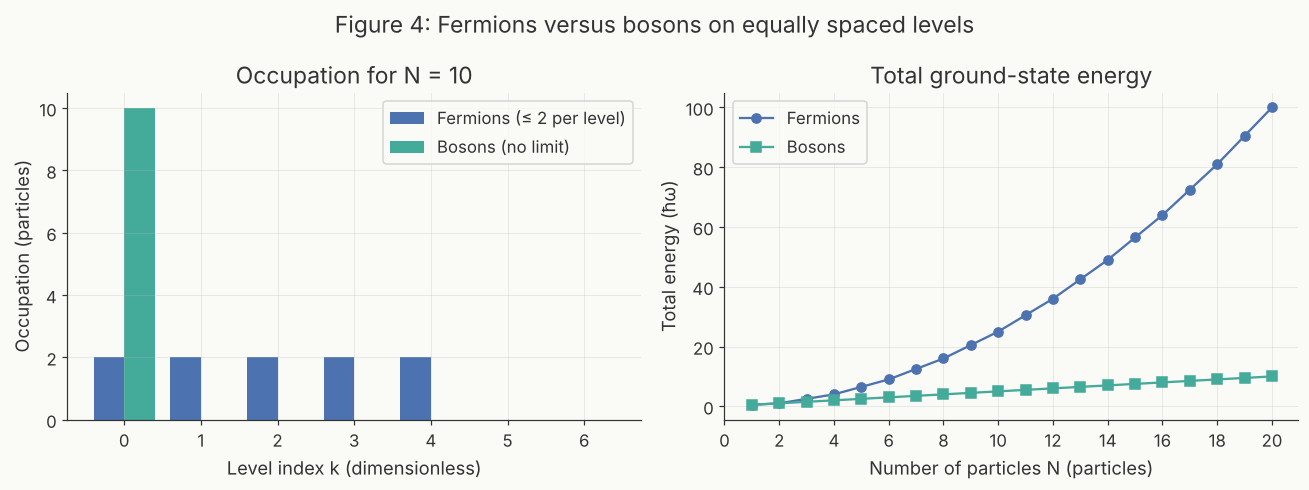

In [18]:
# Cell 32 — Figure 4: occupations for N = 10 and total energy against N
N_values = np.arange(1, 21)
E_f = np.array([total_energy(fill_levels(N, FERMION_MAX)) for N in N_values])
E_b = np.array([total_energy(fill_levels(N, boson_max(N))) for N in N_values])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Left panel: occupation of each level for N = 10 (first 7 levels shown).
k_shown = np.arange(7)
width = 0.4
ax1.bar(k_shown - width / 2, occ_fermions[k_shown], width, color=COLORS["blue"], label="Fermions (≤ 2 per level)")
ax1.bar(k_shown + width / 2, occ_bosons[k_shown], width, color=COLORS["teal"], label="Bosons (no limit)")
ax1.set_xticks(k_shown)
ax1.set_xlabel("Level index k (dimensionless)")
ax1.set_ylabel("Occupation (particles)")
ax1.set_title(f"Occupation for N = {N_EXAMPLE}")
ax1.legend()

# Right panel: total ground-state energy against N.
ax2.plot(N_values, E_f, marker="o", color=COLORS["blue"], label="Fermions")
ax2.plot(N_values, E_b, marker="s", color=COLORS["teal"], label="Bosons")
ax2.set_xticks(np.arange(0, 21, 2))      # whole numbers only
ax2.set_xlabel("Number of particles N (particles)")
ax2.set_ylabel("Total energy (ħω)")
ax2.set_title("Total ground-state energy")
ax2.legend()

fig.suptitle("Figure 4: Fermions versus bosons on equally spaced levels", fontsize=FONT["title"])
fig.tight_layout()
plt.show()

*Figure 4 caption:* Left: for N = 10 all bosons occupy the lowest level (k = 0) while fermions fill levels 0 to 4. Right: total ground-state energy (in units of ħω) versus N. Fermion energy increases approximately as N² while boson energy increases linearly. At N = 10 the energies are 25 ħω (fermions) and 5 ħω (bosons).

## Section 8 — Interpretation, limitations, AI log and references

### 8.1 Interpretation of the results

**1. How the periodic table comes out of two rules**

Looking at all our results together, the periodic table comes from just two simple ideas. The Pauli principle decides how many electrons each subshell can hold, and the Madelung rule decides the order they fill in. When we combine them, we get period lengths of 2, 8, 8 and 18, which is exactly the repeating pattern shown in Figure 1. Our code never told the model where a period starts or ends; the pattern came out on its own. Cr and Cu are the only places where the pattern breaks, and they show that real atoms sometimes prefer a more stable arrangement over the simple filling order.

**2. Why the energy depends on l and not only on n**

Filling the subshells by n alone failed for ten elements, while the Madelung rule failed for only two, as Figure 3 shows. This difference tells us something important: in atoms with more than one electron, the energy of a subshell depends on its shape (l), not just on its shell number (n). This is different from hydrogen, where only n matters. So the other electrons in the atom change the order of the energy levels, and that change is what puts 4s before 3d.

**3. What the α study tells us about the Madelung rule**

The α study shows how strongly the energy has to depend on l for the model to work. For 4s to fill before 3d, its value of n + αl must be smaller:

$$4 < 3 + 2\alpha$$

$$\alpha > 0.5$$

Only a narrow range of α (about 0.55 to 1) gives the correct configurations, and Figure 2 shows how quickly the agreement drops outside this window. The Madelung rule (α = 1) sits right at the edge of that range. This means it is not an exact law of nature. It is an empirical rule that works very well for Z = 1 to 36 but is not derived from first principles.

**4. Why the Pauli principle matters**

Comparing fermions and bosons shows what the Pauli principle does to a system of particles. Fermions are forced to stack up into higher levels, so their total energy grows much faster than that of bosons, as seen in Figure 4. For atoms, this has a big consequence: if electrons were bosons, they would all fall into the 1s orbital. There would be no shells, no periods and no periodic table. So the Pauli principle is the real reason atoms have structure, and the reason the elements behave the way they do.

### 8.2 Limitations of the model

Our model gives the correct configuration for all 36 elements, but that result needs some context. Below are the main places where the model is simplified, and what this means for our results.

**1. It sorts subshells instead of calculating energies**

The model never works out how much energy a subshell actually has. It simply puts the subshells in order using n + l, and it ignores how the electrons interact with each other, through their repulsion and exchange energy. Those interactions are what make a half-filled or completely filled 3d subshell more stable, so without them the model has no way of knowing that Cr and Cu are special. We had to type their correct configurations into the code ourselves. In other words, the model gets these two elements right only because we gave it the answer.

**2. It would not work for heavier elements**

Within the range of the assignment, up to krypton, the model works well. However, it cannot be extended just by increasing Z. Beyond krypton the Madelung rule fails much more often, in elements such as niobium, molybdenum, ruthenium, rhodium, palladium and silver. Our list of exceptions only contains Cr and Cu, so the code would simply give the wrong answer for all of these. In heavy atoms the subshell energies are very close together, so small effects that the rule ignores, such as relativity, are enough to change the filling order. Keeping the model correct would mean adding more and more exceptions by hand.

**3. It only describes neutral atoms in their ground state**

The code always places exactly Z electrons, so every atom it builds is neutral and in its lowest energy state. There is no way to give it a charge, which means it cannot describe ions. This is a real gap, because the filling order changes once an atom is ionised: the 3d subshell drops below 4s, and the 4s electrons are the first to leave. Iron, for example, becomes Fe²⁺ = [Ar] 3d⁶, not [Ar] 3d⁴ 4s². The model also cannot handle excited states, where an electron has moved up to a higher subshell.

**4. The fermion–boson comparison is an idealised picture**

In our extension, each level has the energy (k + ½)ħω, so the levels are evenly spaced like those of a harmonic oscillator. Real atomic levels are not evenly spaced, and they have shapes and angular momentum that our simple levels do not. This part of the model is useful for showing the basic difference between fermions and bosons, but it does not describe the electrons in a real atom.

### 8.3 AI log

1. **Pauli principle video project:**<br>
   <https://claude.ai/share/244975fa-767f-4626-b39d-648dc1cc70ab>

2. **Project code with error found:**<br>
   <https://claude.ai/share/8ccf0904-7464-42a1-aef1-0a621c0ae9c1>

3. **Code update with text:**<br>
   <https://claude.ai/share/5710205f-81db-44c9-b222-dbbc003eec01>

4. **Claude Code website:**<br>
   This session was done in Claude Code, which does not provide a shareable link. In it, we asked Claude to build a website for our project and publish it with a public link using GitHub Pages.

### 8.4 Reflection on using AI

**1. How We Used AI**

We used Claude to help us write our Python code, create the graphs and fix errors. Our job was to check every result against the NIST data and make sure we understood each part of the code.

**2. An AI Mistake We Found and Fixed**

The AI wrote the test `assert len(SYMBOLS) == Z_MAX`, which only works when exactly 36 elements are studied. We found the problem when we changed Z_MAX to a value other than 36: Cell 5 stopped with an `AssertionError`. For smaller values, Figure 1 also crashed with an `IndexError`, because it tried to label elements outside the chosen range, such as Cr, Cu and Kr.

We explained the problem to the AI and asked it to fix it. The test was changed to `>= Z_MAX`, a clear error message was added for values outside 1 to 36, and the figures now only label elements inside the range. To check the fix, we ran the whole notebook for every value of Z_MAX from 1 to 36, and it worked each time.

**3. Strengths and Limitations of AI**

AI saved us a lot of time and made our code clear and well organised. However, it made hidden assumptions, like always using 36 elements, which we only discovered by testing the code ourselves.

**4. What We Learned**

Code can look correct when it is only tested with one value. Next time, we will test with different parameter values from the start.

### 8.5 References

1. A. Kramida, Yu. Ralchenko, J. Reader and NIST ASD Team, *NIST Atomic Spectra Database*, Ionization Energies Data, National Institute of Standards and Technology, Gaithersburg, MD. [NIST ASD Ionization Energies](https://physics.nist.gov/cgi-bin/ASD/ie.pl?spectra=H-DS+i&units=1&at_num_out=on&el_name_out=on&shells_out=on&level_out=on&e_out=0&unc_out=on&biblio=on) (accessed November 2026).

2. W. C. Martin, A. Musgrove, S. Kotochigova and J. E. Sansonetti, *Ground Levels and Ionization Energies for the Neutral Atoms*, NIST Standard Reference Database 111. [NIST SRD 111](https://www.nist.gov/pml/ground-levels-and-ionization-energies-neutral-atoms), DOI: [10.18434/T42P4C](https://doi.org/10.18434/T42P4C)

3. A. Beiser, *Concepts of Modern Physics*, 6th ed. (McGraw-Hill, 2002), Ch. 7 "Many-Electron Atoms" and Ch. 9 "Statistical Mechanics".

4. Anthropic, *Claude* (AI assistant), used for code generation and debugging, November 2026.